In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# File path
file_path = Path(r"C:\Users\yashp\Desktop\ANCP_Project\CP.xlsx")

# Check whether the file exists
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

# Display available Excel sheets
xls = pd.ExcelFile(file_path)
print("Available sheets:", xls.sheet_names)

# Load the first sheet
df = pd.read_excel(file_path, sheet_name=0)

# Display dataset information
print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Available sheets: ['Sheet1']

Dataset loaded successfully!
Shape: (1320, 28)

Column names:
['circle', 'report_month', 'prev_month', 'release_date', 'total_prev', 'total_curr', 'total_net_addition', 'vi_vlr_pct', 'mnp_ports_month', 'mnp_kind', 'mnp_prev_value', 'mnp_curr_value', 'airtel_prev', 'airtel_curr', 'rcom_prev', 'rcom_curr', 'vi_prev', 'vi_curr', 'bsnl_prev', 'bsnl_curr', 'vno_prev', 'vno_curr', 'mtnl_prev', 'mtnl_curr', 'jio_prev', 'jio_curr', 'Subscriber change(VI)', 'Subscriber growth rate(VI)']


,circle,report_month,prev_month,release_date,total_prev,total_curr,total_net_addition,vi_vlr_pct,mnp_ports_month,mnp_kind,mnp_prev_value,mnp_curr_value,airtel_prev,airtel_curr,rcom_prev,rcom_curr,vi_prev,vi_curr,bsnl_prev,bsnl_curr,vno_prev,vno_curr,mtnl_prev,mtnl_curr,jio_prev,jio_curr,Subscriber change(VI),Subscriber growth rate(VI)
0,Andhra Pradesh,2021-09-01,2021-08-01,2021-11-22,87635003,86396038,-1238965,88.530,460000,cumulative,48.230,48.690,31186566,31193079,0,0,14897868,14768586,9040658,9043969,0,0,0,0,32509911,31390404,-129282,-0.868
1,Assam,2021-09-01,2021-08-01,2021-11-22,25238921,24353494,-885427,87.090,60000,cumulative,4.370,4.430,9563472,9666469,0,0,2942512,2896364,3085783,3097802,0,0,0,0,9647154,8692859,-46148,-1.568
2,Bihar,2021-09-01,2021-08-01,2021-11-22,87206868,86938036,-268832,82.450,730000,cumulative,30.290,31.020,36455259,36289924,0,0,11076397,10973747,5592809,5543665,0,0,0,0,34082403,34130700,-102650,-0.927
3,Delhi,2021-09-01,2021-08-01,2021-11-22,54128991,52403354,-1725637,73.320,450000,cumulative,30.640,31.090,15797812,15829346,348,327,15803961,15812011,0,0,0,0,2156829,2155755,20370041,18605915,8050,0.051
4,Gujarat,2021-09-01,2021-08-01,2021-11-22,70052994,68687658,-1365336,90.940,720000,cumulative,42.430,43.150,11967790,11842855,167,167,24454206,24305580,5669105,5676308,0,0,0,0,27961726,26862748,-148626,-0.608


In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

structure = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_pct": [float(df[c].isna().mean() * 100) for c in df.columns],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns],
})
display(structure)

if "circle" in df:
    print("\nUnique circles:", df["circle"].nunique())
if "report_month" in df:
    print("First report month:", df["report_month"].min())
    print("Last report month :", df["report_month"].max())
    print("Distinct months   :", df["report_month"].nunique())

Shape: (1320, 28)

Column names:
['circle', 'report_month', 'prev_month', 'release_date', 'total_prev', 'total_curr', 'total_net_addition', 'vi_vlr_pct', 'mnp_ports_month', 'mnp_kind', 'mnp_prev_value', 'mnp_curr_value', 'airtel_prev', 'airtel_curr', 'rcom_prev', 'rcom_curr', 'vi_prev', 'vi_curr', 'bsnl_prev', 'bsnl_curr', 'vno_prev', 'vno_curr', 'mtnl_prev', 'mtnl_curr', 'jio_prev', 'jio_curr', 'Subscriber change(VI)', 'Subscriber growth rate(VI)']


,column,dtype,missing_count,missing_pct,unique_values
0,circle,object,0,0.000,22
1,report_month,datetime64[ns],0,0.000,60
2,prev_month,datetime64[ns],0,0.000,60
3,release_date,datetime64[ns],88,6.667,56
4,total_prev,int64,0,0.000,1320
5,total_curr,int64,0,0.000,1320
6,total_net_addition,int64,0,0.000,1318
7,vi_vlr_pct,float64,0,0.000,985
8,mnp_ports_month,int64,0,0.000,229
9,mnp_kind,object,0,0.000,2



Unique circles: 22
First report month: 2021-09-01 00:00:00
Last report month : 2026-08-01 00:00:00
Distinct months   : 60


In [4]:
# Missing values
missing = (df.isna().sum().rename("missing_count").to_frame())
missing["missing_pct"] = (df.isna().mean() * 100).round(2)
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)
print("Columns with missing values:")
display(missing if not missing.empty else pd.DataFrame({"message": ["No missing values found."]}))

# Duplicate rows and duplicate circle-month keys
print("Exact duplicate rows:", int(df.duplicated().sum()))
if {"circle", "report_month"}.issubset(df.columns):
    duplicate_keys = df.duplicated(["circle", "report_month"], keep=False)
    print("Rows involved in duplicate circle-month keys:", int(duplicate_keys.sum()))
    if duplicate_keys.any():
        display(df.loc[duplicate_keys, ["circle", "report_month"]].sort_values(["circle", "report_month"]).head(30))

# Coverage: expected 1 row per circle-month combination
if {"circle", "report_month"}.issubset(df.columns):
    circles = sorted(df["circle"].dropna().unique())
    months = sorted(df["report_month"].dropna().unique())
    expected_keys = pd.MultiIndex.from_product([circles, months], names=["circle", "report_month"])
    observed_keys = pd.MultiIndex.from_frame(df[["circle", "report_month"]].drop_duplicates())
    missing_keys = expected_keys.difference(observed_keys)
    print(f"Expected circle-month combinations: {len(expected_keys):,}")
    print(f"Observed unique combinations       : {len(observed_keys):,}")
    print(f"Missing combinations               : {len(missing_keys):,}")
    if len(missing_keys):
        display(missing_keys.to_frame(index=False).head(30))

# Check reported total change arithmetic
if {"total_prev", "total_curr", "total_net_addition"}.issubset(df.columns):
    df["total_change_calculated"] = df["total_curr"] - df["total_prev"]
    mismatch = ~np.isclose(df["total_change_calculated"], df["total_net_addition"], equal_nan=True)
    print("Total net-addition arithmetic mismatches:", int(mismatch.sum()))
    if mismatch.any():
        display(df.loc[mismatch, ["circle", "report_month", "total_prev", "total_curr", "total_net_addition", "total_change_calculated"]].head(20))

# Publication dates are kept as metadata; missing release dates should not be invented.
if "release_date" in df:
    print("Missing release dates:", int(df["release_date"].isna().sum()))

Columns with missing values:


,missing_count,missing_pct
release_date,88,6.670


Exact duplicate rows: 0
Rows involved in duplicate circle-month keys: 0
Expected circle-month combinations: 1,320
Observed unique combinations       : 1,320
Missing combinations               : 0
Total net-addition arithmetic mismatches: 0
Missing release dates: 88


In [5]:
# These are the operator prefixes present in CP.xlsx.
operators = ["vi", "airtel", "jio", "bsnl", "rcom", "vno", "mtnl"]
created_columns = []

for op in operators:
    prev_col, curr_col = f"{op}_prev", f"{op}_curr"
    if prev_col not in df.columns or curr_col not in df.columns:
        print(f"Skipping {op}: missing {prev_col} or {curr_col}")
        continue

    # Absolute change in subscriber count.
    change_col = f"{op}_subscriber_change"
    df[change_col] = df[curr_col] - df[prev_col]
    created_columns.append(change_col)

    # Percentage change. If previous count is zero, percentage change is undefined (NaN).
    growth_col = f"{op}_subscriber_change_pct"
    denominator = df[prev_col].where(df[prev_col] != 0)
    df[growth_col] = (df[curr_col] - df[prev_col]) / denominator * 100
    created_columns.append(growth_col)

    # Current-month share of the total reported subscriber base.
    if "total_curr" in df.columns:
        share_col = f"{op}_market_share_pct"
        total_denominator = df["total_curr"].where(df["total_curr"] != 0)
        df[share_col] = df[curr_col] / total_denominator * 100
        created_columns.append(share_col)

# Create same measures for the overall reported subscriber base.
if {"total_prev", "total_curr"}.issubset(df.columns):
    df["total_subscriber_change"] = df["total_curr"] - df["total_prev"]
    df["total_subscriber_change_pct"] = (
        df["total_subscriber_change"] / df["total_prev"].where(df["total_prev"] != 0) * 100
    )
    created_columns += ["total_subscriber_change", "total_subscriber_change_pct"]

# Verify existing Vi calculations against the values we just recalculated.
if "Subscriber change(VI)" in df and "vi_subscriber_change" in df:
    diff = df["Subscriber change(VI)"] - df["vi_subscriber_change"]
    print("Rows where original Vi change differs from recalculation:", int((diff.abs() > 1e-8).sum()))
if "Subscriber growth rate(VI)" in df and "vi_subscriber_change_pct" in df:
    diff = df["Subscriber growth rate(VI)"] - df["vi_subscriber_change_pct"]
    print("Rows where original Vi growth % differs from recalculation:", int((diff.abs() > 1e-8).sum()))

print(f"Created {len(created_columns)} derived columns.")
display(df[["circle", "report_month"] + [c for c in created_columns if c in df.columns]].head())

Rows where original Vi change differs from recalculation: 0
Rows where original Vi growth % differs from recalculation: 0
Created 23 derived columns.


,circle,report_month,vi_subscriber_change,vi_subscriber_change_pct,vi_market_share_pct,airtel_subscriber_change,airtel_subscriber_change_pct,airtel_market_share_pct,jio_subscriber_change,jio_subscriber_change_pct,jio_market_share_pct,bsnl_subscriber_change,bsnl_subscriber_change_pct,bsnl_market_share_pct,rcom_subscriber_change,rcom_subscriber_change_pct,rcom_market_share_pct,vno_subscriber_change,vno_subscriber_change_pct,vno_market_share_pct,mtnl_subscriber_change,mtnl_subscriber_change_pct,mtnl_market_share_pct,total_subscriber_change,total_subscriber_change_pct
0,Andhra Pradesh,2021-09-01,-129282,-0.868,17.094,6513,0.021,36.105,-1119507,-3.444,36.333,3311,0.037,10.468,0,NaN,0.000,0,NaN,0.000,0,NaN,0.000,-1238965,-1.414
1,Assam,2021-09-01,-46148,-1.568,11.893,102997,1.077,39.692,-954295,-9.892,35.695,12019,0.389,12.720,0,NaN,0.000,0,NaN,0.000,0,NaN,0.000,-885427,-3.508
2,Bihar,2021-09-01,-102650,-0.927,12.622,-165335,-0.454,41.742,48297,0.142,39.259,-49144,-0.879,6.377,0,NaN,0.000,0,NaN,0.000,0,NaN,0.000,-268832,-0.308
3,Delhi,2021-09-01,8050,0.051,30.174,31534,0.200,30.207,-1764126,-8.660,35.505,0,NaN,0.000,-21,-6.034,0.001,0,NaN,0.000,-1074,-0.050,4.114,-1725637,-3.188
4,Gujarat,2021-09-01,-148626,-0.608,35.386,-124935,-1.044,17.242,-1098978,-3.930,39.109,7203,0.127,8.264,0,0.000,0.000,0,NaN,0.000,0,NaN,0.000,-1365336,-1.949


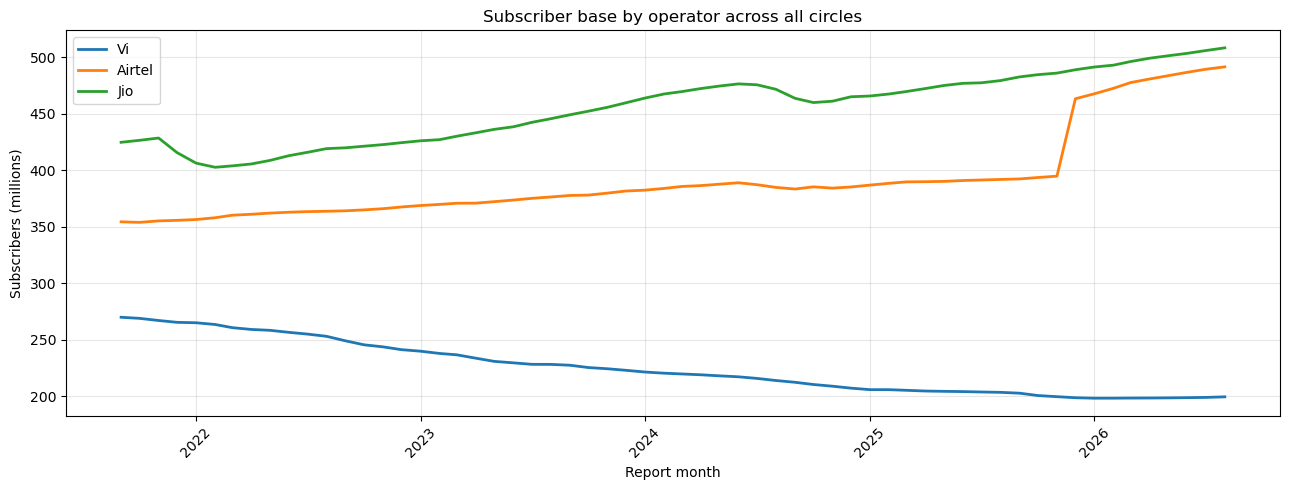

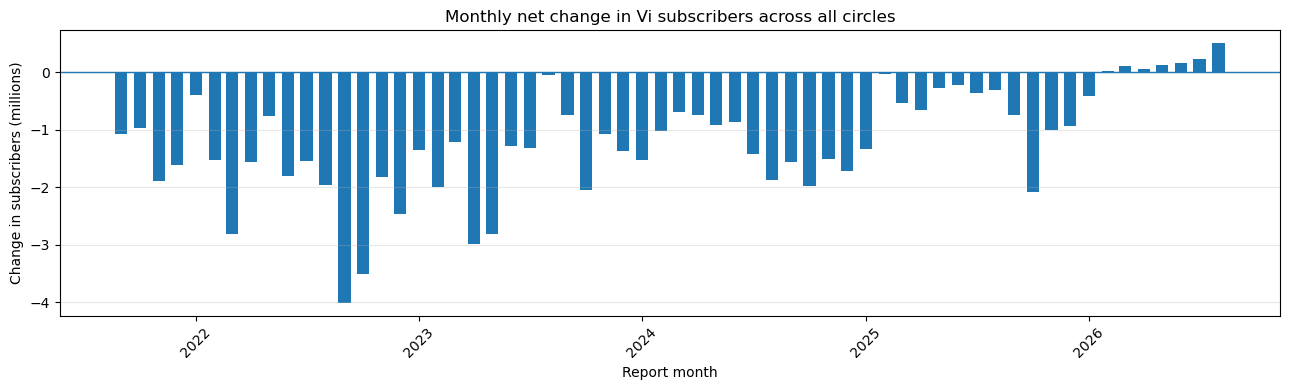

,report_month,total_subscribers,vi_subscribers,airtel_subscribers,jio_subscribers,total_net_addition,vi_change
48,2025-09-01,1170440642,202806789,392412039,482702876,3409791,-744222
49,2025-10-01,1171874735,200723171,393664913,484700719,1434093,-2083618
50,2025-11-01,1173881921,199712037,394880318,486089648,2007186,-1011134
51,2025-12-01,1244196237,198771306,463384389,489050236,7238559,-940731
52,2026-01-01,1250893999,198359969,467791050,491487786,6697762,-411337
53,2026-02-01,1257293404,198381896,472648878,493111983,6399405,21927
54,2026-03-01,1265726807,198484795,477743846,496339525,8433403,102899
55,2026-04-01,1271904668,198538052,480883074,499282168,6177861,53257
56,2026-05-01,1276998869,198659341,483809981,501436636,5094201,121289
57,2026-06-01,1282382284,198823098,486799957,503583616,5383415,163757


In [6]:
monthly = df.groupby("report_month", as_index=False).agg(
    total_subscribers=("total_curr", "sum"),
    vi_subscribers=("vi_curr", "sum"),
    airtel_subscribers=("airtel_curr", "sum"),
    jio_subscribers=("jio_curr", "sum"),
    total_net_addition=("total_net_addition", "sum"),
    vi_change=("vi_subscriber_change", "sum"),
)
monthly = monthly.sort_values("report_month")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly["report_month"], monthly["vi_subscribers"] / 1e6, label="Vi", linewidth=2)
ax.plot(monthly["report_month"], monthly["airtel_subscribers"] / 1e6, label="Airtel", linewidth=2)
ax.plot(monthly["report_month"], monthly["jio_subscribers"] / 1e6, label="Jio", linewidth=2)
ax.set_title("Subscriber base by operator across all circles")
ax.set_xlabel("Report month")
ax.set_ylabel("Subscribers (millions)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(monthly["report_month"], monthly["vi_change"] / 1e6, width=20)
ax.axhline(0, linewidth=1)
ax.set_title("Monthly net change in Vi subscribers across all circles")
ax.set_xlabel("Report month")
ax.set_ylabel("Change in subscribers (millions)")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly.tail(12))

In [ ]:
#- Vi: Its total subscriber base falls from about 202.8 million in September 2025 to 199.6 million in August 2026.
#- Airtel: Its recorded subscriber base increases over the displayed period.
#- Jio: Its recorded subscriber base also increases over the displayed period.
#This gives us an initial picture of how Vi's subscriber base compares with its competitors nationally.
#Vi experienced consecutive monthly declines from September 2025 through January 2026. From February through August 2026, its recorded subscriber base increased each month.

,operator,mean_monthly_growth_pct,median_monthly_growth_pct,share_rows_declining_pct,total_change_across_all_rows,growth_values_undefined
6,MTNL,-4.325,-0.345,95.000,-3119002,1200
4,RCOM,-4.002,0.000,40.104,-6263,744
0,VI,-0.597,-0.553,78.182,-71498781,0
3,BSNL,-0.309,-0.056,54.000,-20599517,120
2,JIO,0.148,0.408,27.273,64570661,0
1,AIRTEL,0.308,0.311,23.258,74332213,0
5,VNO,3.715,3.256,14.634,20251,1279


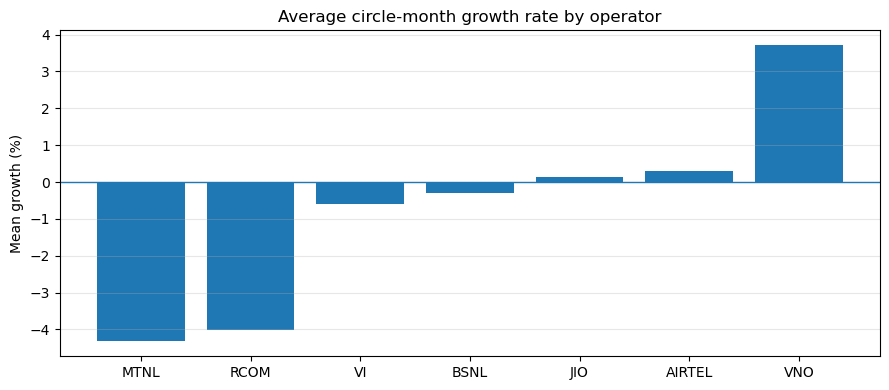

In [7]:
growth_cols = [f"{op}_subscriber_change_pct" for op in operators if f"{op}_subscriber_change_pct" in df]
change_cols = [f"{op}_subscriber_change" for op in operators if f"{op}_subscriber_change" in df]

operator_summary = []
for op in operators:
    gcol, ccol = f"{op}_subscriber_change_pct", f"{op}_subscriber_change"
    if gcol in df:
        valid = df[gcol].dropna()
        operator_summary.append({
            "operator": op.upper(),
            "mean_monthly_growth_pct": valid.mean(),
            "median_monthly_growth_pct": valid.median(),
            "share_rows_declining_pct": (valid < 0).mean() * 100 if len(valid) else np.nan,
            "total_change_across_all_rows": df[ccol].sum(),
            "growth_values_undefined": int(df[gcol].isna().sum()),
        })
operator_summary = pd.DataFrame(operator_summary).sort_values("mean_monthly_growth_pct")
display(operator_summary)

if not operator_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(operator_summary["operator"], operator_summary["mean_monthly_growth_pct"])
    ax.axhline(0, linewidth=1)
    ax.set_title("Average circle-month growth rate by operator")
    ax.set_ylabel("Mean growth (%)")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

,circle,average_vi_growth_pct,median_vi_growth_pct,vi_declining_months,months_observed,first_vi_subscribers,latest_vi_subscribers,total_vi_change,declining_month_share_pct
14,North East,-1.284,-1.153,55,60,1287316,590167,-697149,91.667
1,Assam,-1.092,-1.235,45,60,2942512,1514641,-1427871,75.000
7,J&K,-0.935,-1.246,43,60,469335,261962,-207373,71.667
0,Andhra Pradesh,-0.880,-0.826,57,60,14897868,8753514,-6144354,95.000
11,Madhya Pradesh,-0.864,-0.776,55,60,20896193,12392757,-8503436,91.667
21,West Bengal,-0.819,-0.660,57,60,16472500,10048058,-6424442,95.000
20,UP West,-0.780,-0.614,56,60,19325518,12062015,-7263503,93.333
16,Punjab,-0.735,-0.749,52,60,8781165,5623167,-3157998,86.667
6,Himachal Pradesh,-0.724,-0.731,48,60,612917,395022,-217895,80.000
2,Bihar,-0.640,-0.638,42,60,11076397,7504851,-3571546,70.000


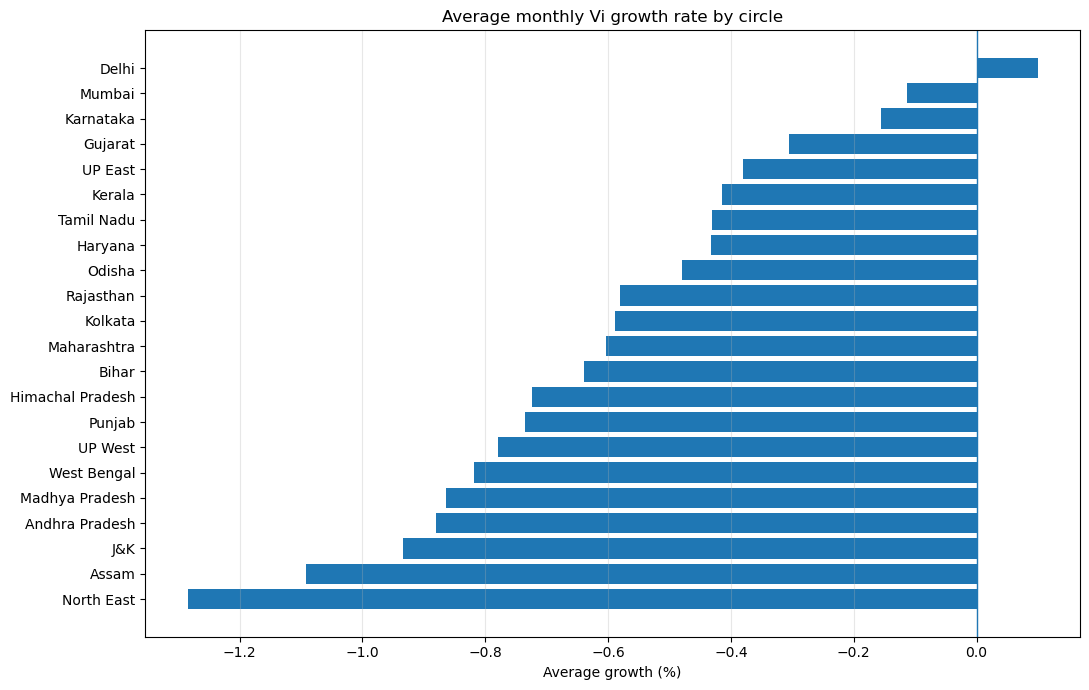

Circles with the lowest average Vi growth:


,circle,average_vi_growth_pct,declining_month_share_pct,total_vi_change
14,North East,-1.284,91.667,-697149
1,Assam,-1.092,75.000,-1427871
7,J&K,-0.935,71.667,-207373
0,Andhra Pradesh,-0.880,95.000,-6144354
11,Madhya Pradesh,-0.864,91.667,-8503436


Circles with the highest average Vi growth:


,circle,average_vi_growth_pct,declining_month_share_pct,total_vi_change
3,Delhi,0.099,38.333,938281
13,Mumbai,-0.113,50.000,-770334
8,Karnataka,-0.156,58.333,-817680
4,Gujarat,-0.306,73.333,-4129208
19,UP East,-0.380,73.333,-4307004


In [8]:
circle_summary = df.groupby("circle", as_index=False).agg(
    average_vi_growth_pct=("vi_subscriber_change_pct", "mean"),
    median_vi_growth_pct=("vi_subscriber_change_pct", "median"),
    vi_declining_months=("vi_subscriber_change_pct", lambda s: int((s < 0).sum())),
    months_observed=("vi_subscriber_change_pct", "count"),
    first_vi_subscribers=("vi_prev", "first"),
    latest_vi_subscribers=("vi_curr", "last"),
    total_vi_change=("vi_subscriber_change", "sum"),
)
circle_summary["declining_month_share_pct"] = circle_summary["vi_declining_months"] / circle_summary["months_observed"] * 100
circle_summary = circle_summary.sort_values("average_vi_growth_pct")
display(circle_summary)

fig, ax = plt.subplots(figsize=(11, 7))
plot_data = circle_summary.sort_values("average_vi_growth_pct")
ax.barh(plot_data["circle"], plot_data["average_vi_growth_pct"])
ax.axvline(0, linewidth=1)
ax.set_title("Average monthly Vi growth rate by circle")
ax.set_xlabel("Average growth (%)")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Circles with the lowest average Vi growth:")
display(circle_summary.head(5)[["circle", "average_vi_growth_pct", "declining_month_share_pct", "total_vi_change"]])
print("Circles with the highest average Vi growth:")
display(circle_summary.tail(5).sort_values("average_vi_growth_pct", ascending=False)[["circle", "average_vi_growth_pct", "declining_month_share_pct", "total_vi_change"]])

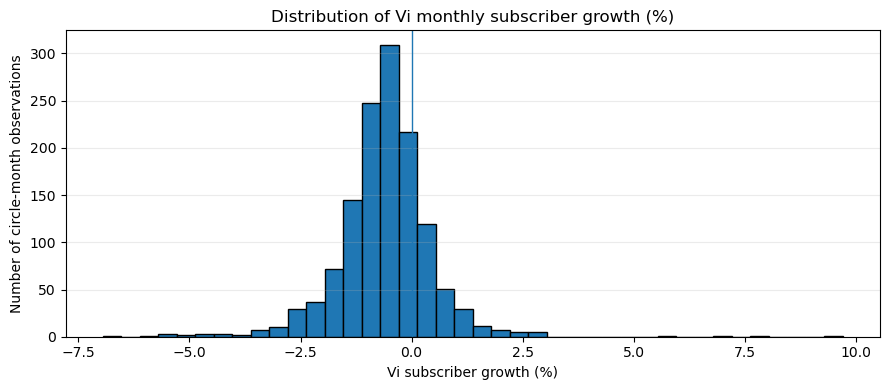

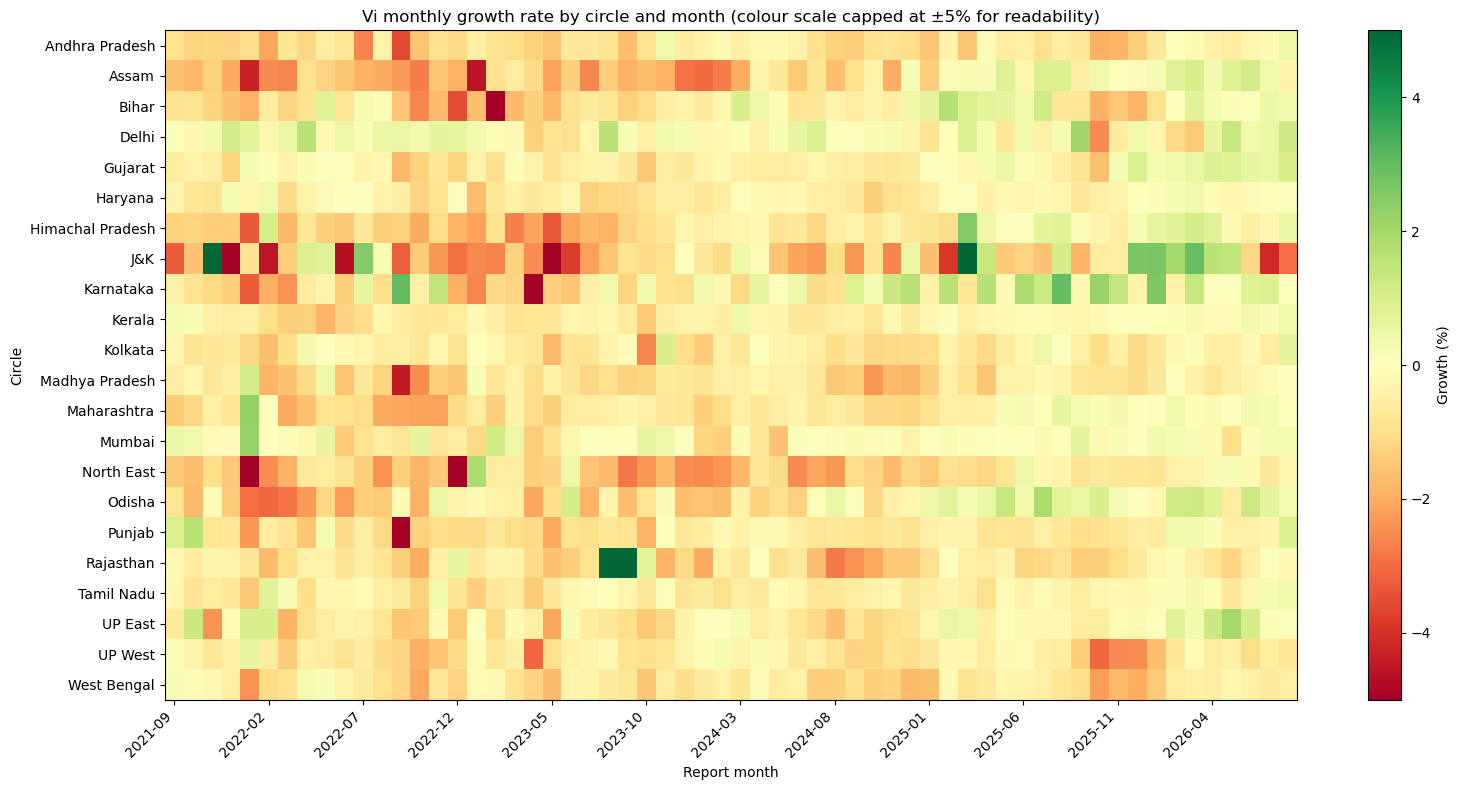

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
values = df["vi_subscriber_change_pct"].replace([np.inf, -np.inf], np.nan).dropna()
ax.hist(values, bins=40, edgecolor="black")
ax.axvline(0, linewidth=1)
ax.set_title("Distribution of Vi monthly subscriber growth (%)")
ax.set_xlabel("Vi subscriber growth (%)")
ax.set_ylabel("Number of circle-month observations")
ax.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

heat = df.pivot_table(index="circle", columns="report_month", values="vi_subscriber_change_pct", aggfunc="mean")
fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(heat.values, aspect="auto", interpolation="nearest", cmap="RdYlGn", vmin=-5, vmax=5)
ax.set_title("Vi monthly growth rate by circle and month (colour scale capped at ±5% for readability)")
ax.set_xlabel("Report month")
ax.set_ylabel("Circle")
ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels(heat.index)
step = max(1, len(heat.columns) // 12)
ax.set_xticks(np.arange(0, len(heat.columns), step))
ax.set_xticklabels([heat.columns[i].strftime("%Y-%m") for i in range(0, len(heat.columns), step)], rotation=45, ha="right")
fig.colorbar(im, ax=ax, label="Growth (%)")
plt.tight_layout()
plt.show()

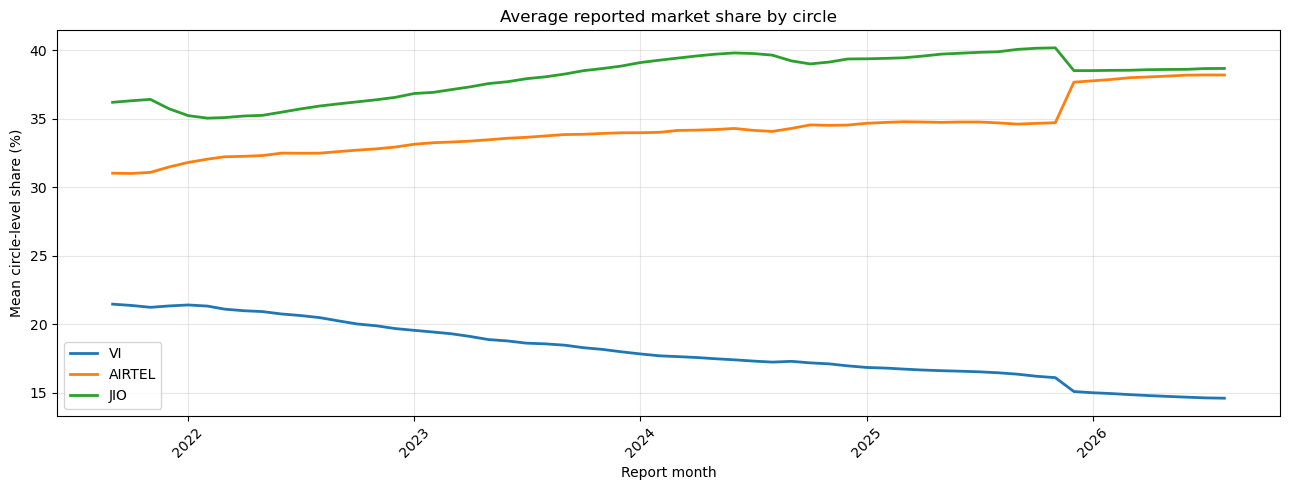

,report_month,vi_market_share_pct,airtel_market_share_pct,jio_market_share_pct,bsnl_market_share_pct,rcom_market_share_pct,vno_market_share_pct,mtnl_market_share_pct
48,2025-09-01,16.359,34.603,40.060,8.953,0.000,0.000,0.025
49,2025-10-01,16.209,34.658,40.141,8.967,0.000,0.000,0.025
50,2025-11-01,16.107,34.706,40.169,8.994,0.000,0.000,0.024
51,2025-12-01,15.092,37.665,38.508,8.715,0.000,0.000,0.019
52,2026-01-01,15.004,37.766,38.510,8.702,0.000,0.000,0.019
53,2026-02-01,14.941,37.869,38.528,8.644,0.000,0.000,0.018
54,2026-03-01,14.867,37.992,38.535,8.589,0.000,0.000,0.017
55,2026-04-01,14.797,38.048,38.576,8.565,0.000,0.000,0.014
56,2026-05-01,14.738,38.109,38.593,8.546,0.000,0.000,0.013
57,2026-06-01,14.682,38.178,38.601,8.527,0.000,0.000,0.012


Note: the chart uses the mean of circle-level shares. It is not the same as nationwide operator share weighted by subscriber counts.


In [10]:
share_cols = [f"{op}_market_share_pct" for op in ["vi", "airtel", "jio", "bsnl", "rcom", "vno", "mtnl"] if f"{op}_market_share_pct" in df]
share_summary = df.groupby("report_month", as_index=False)[share_cols].mean().sort_values("report_month")

fig, ax = plt.subplots(figsize=(13, 5))
for op in ["vi", "airtel", "jio"]:
    col = f"{op}_market_share_pct"
    if col in share_summary:
        ax.plot(share_summary["report_month"], share_summary[col], label=op.upper(), linewidth=2)
ax.set_title("Average reported market share by circle")
ax.set_xlabel("Report month")
ax.set_ylabel("Mean circle-level share (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(share_summary.tail(12))
print("Note: the chart uses the mean of circle-level shares. It is not the same as nationwide operator share weighted by subscriber counts.")


count   1,320.000
mean       87.625
std         9.448
min        49.130
1%         52.637
5%         68.776
25%        85.310
50%        89.860
75%        92.875
95%        96.831
99%       107.388
max       118.610
Name: vi_vlr_pct, dtype: float64
VLR values above 100%: 45
VLR values below 0%: 0


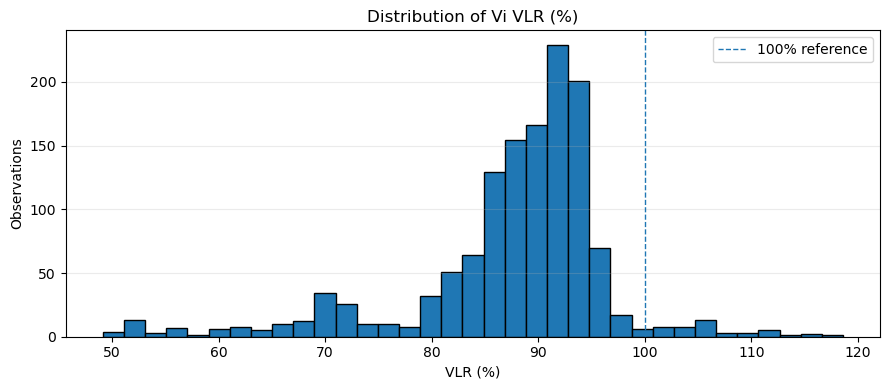

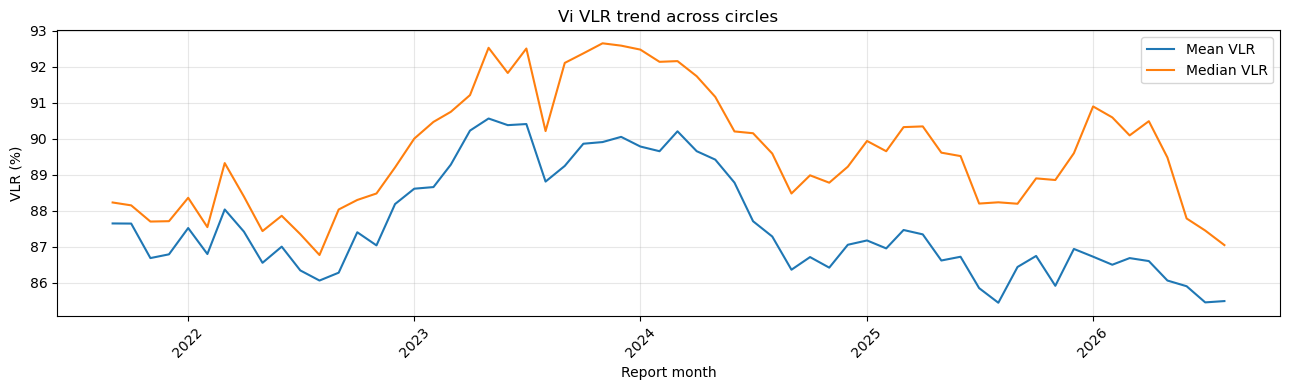

In [11]:
if "vi_vlr_pct" in df.columns:
    print(df["vi_vlr_pct"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
    print("VLR values above 100%:", int((df["vi_vlr_pct"] > 100).sum()))
    print("VLR values below 0%:", int((df["vi_vlr_pct"] < 0).sum()))

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(df["vi_vlr_pct"].dropna(), bins=35, edgecolor="black")
    ax.axvline(100, linestyle="--", linewidth=1, label="100% reference")
    ax.set_title("Distribution of Vi VLR (%)")
    ax.set_xlabel("VLR (%)")
    ax.set_ylabel("Observations")
    ax.legend()
    ax.grid(True, axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    vlr_month = df.groupby("report_month", as_index=False).agg(mean_vlr_pct=("vi_vlr_pct", "mean"), median_vlr_pct=("vi_vlr_pct", "median"))
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(vlr_month["report_month"], vlr_month["mean_vlr_pct"], label="Mean VLR")
    ax.plot(vlr_month["report_month"], vlr_month["median_vlr_pct"], label="Median VLR")
    ax.set_title("Vi VLR trend across circles")
    ax.set_xlabel("Report month")
    ax.set_ylabel("VLR (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("vi_vlr_pct is not available in this workbook.")

Rows by MNP reporting kind:


,rows
mnp_kind,
cumulative,1034
monthly,286


Negative mnp_ports_month values: 5
Zero mnp_ports_month values: 0


,circle,report_month,mnp_kind,mnp_prev_value,mnp_curr_value,mnp_ports_month
468,Himachal Pradesh,2023-06-01,cumulative,4.290,3.730,-560000
469,J&K,2023-06-01,cumulative,2.360,2.010,-350000
472,Kolkata,2023-06-01,cumulative,16.540,16.350,-190000
475,Mumbai,2023-06-01,cumulative,31.160,30.740,-420000
476,North East,2023-06-01,cumulative,2.630,2.000,-630000


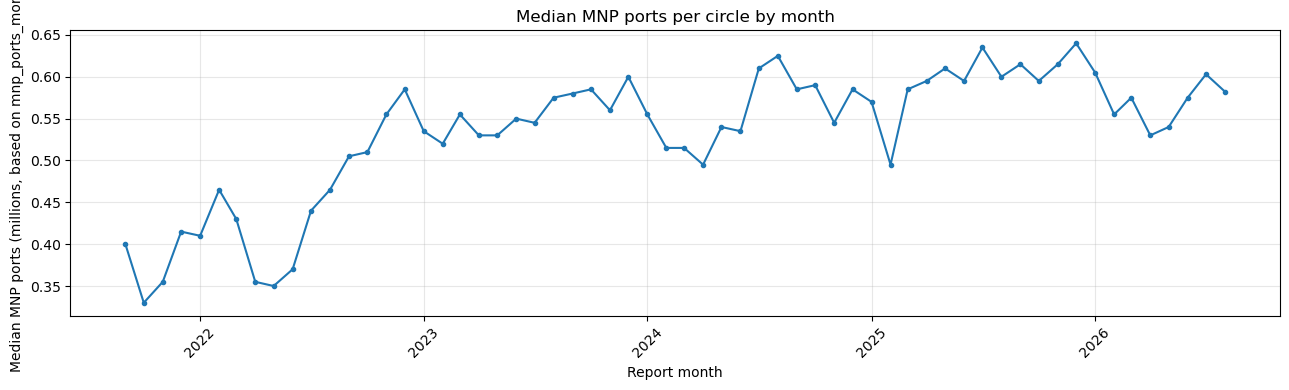

,report_month,median_mnp_ports,total_mnp_ports,negative_rows
48,2025-09-01,"615,000.000",15110000,0
49,2025-10-01,"595,000.000",15040000,0
50,2025-11-01,"615,000.000",14710000,0
51,2025-12-01,"640,000.000",16120000,0
52,2026-01-01,"605,000.000",15990000,0
53,2026-02-01,"555,000.000",14460000,0
54,2026-03-01,"575,000.000",14650000,0
55,2026-04-01,"530,000.000",14760000,0
56,2026-05-01,"540,000.000",14470000,0
57,2026-06-01,"575,000.000",14790000,0


Important: inspect the source definition around changes in mnp_kind. Do not assume the cumulative and monthly source columns are directly comparable.


In [12]:
if "mnp_kind" in df.columns:
    print("Rows by MNP reporting kind:")
    display(df["mnp_kind"].value_counts(dropna=False).rename_axis("mnp_kind").to_frame("rows"))

if "mnp_ports_month" in df.columns:
    print("Negative mnp_ports_month values:", int((df["mnp_ports_month"] < 0).sum()))
    print("Zero mnp_ports_month values:", int((df["mnp_ports_month"] == 0).sum()))
    negative_mnp = df.loc[df["mnp_ports_month"] < 0, [c for c in ["circle", "report_month", "mnp_kind", "mnp_prev_value", "mnp_curr_value", "mnp_ports_month"] if c in df.columns]]
    display(negative_mnp)

    mnp_month = df.groupby("report_month", as_index=False).agg(
        median_mnp_ports=("mnp_ports_month", "median"),
        total_mnp_ports=("mnp_ports_month", "sum"),
        negative_rows=("mnp_ports_month", lambda s: int((s < 0).sum())),
    ).sort_values("report_month")
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(mnp_month["report_month"], mnp_month["median_mnp_ports"] / 1e6, marker="o", markersize=3)
    ax.set_title("Median MNP ports per circle by month")
    ax.set_xlabel("Report month")
    ax.set_ylabel("Median MNP ports (millions, based on mnp_ports_month)")
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(mnp_month.tail(12))

    print("Important: inspect the source definition around changes in mnp_kind. Do not assume the cumulative and monthly source columns are directly comparable.")
else:
    print("mnp_ports_month is not available in this workbook.")

Rows by MNP reporting kind:


,rows
mnp_kind,
cumulative,1034
monthly,286


Negative mnp_ports_month values: 5
Zero mnp_ports_month values: 0


,circle,report_month,mnp_kind,mnp_prev_value,mnp_curr_value,mnp_ports_month
468,Himachal Pradesh,2023-06-01,cumulative,4.290,3.730,-560000
469,J&K,2023-06-01,cumulative,2.360,2.010,-350000
472,Kolkata,2023-06-01,cumulative,16.540,16.350,-190000
475,Mumbai,2023-06-01,cumulative,31.160,30.740,-420000
476,North East,2023-06-01,cumulative,2.630,2.000,-630000


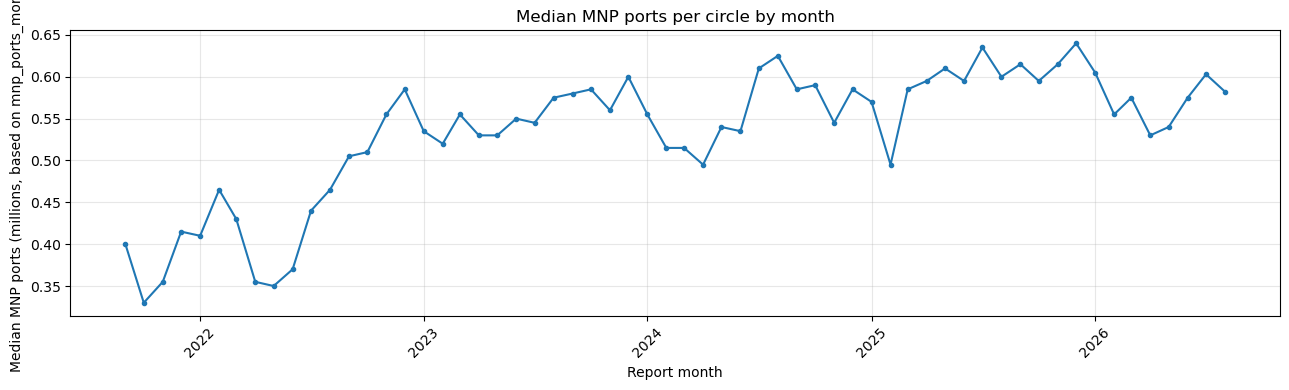

,report_month,median_mnp_ports,total_mnp_ports,negative_rows
48,2025-09-01,"615,000.000",15110000,0
49,2025-10-01,"595,000.000",15040000,0
50,2025-11-01,"615,000.000",14710000,0
51,2025-12-01,"640,000.000",16120000,0
52,2026-01-01,"605,000.000",15990000,0
53,2026-02-01,"555,000.000",14460000,0
54,2026-03-01,"575,000.000",14650000,0
55,2026-04-01,"530,000.000",14760000,0
56,2026-05-01,"540,000.000",14470000,0
57,2026-06-01,"575,000.000",14790000,0


Important: inspect the source definition around changes in mnp_kind. Do not assume the cumulative and monthly source columns are directly comparable.


In [13]:
if "mnp_kind" in df.columns:
    print("Rows by MNP reporting kind:")
    display(df["mnp_kind"].value_counts(dropna=False).rename_axis("mnp_kind").to_frame("rows"))

if "mnp_ports_month" in df.columns:
    print("Negative mnp_ports_month values:", int((df["mnp_ports_month"] < 0).sum()))
    print("Zero mnp_ports_month values:", int((df["mnp_ports_month"] == 0).sum()))
    negative_mnp = df.loc[df["mnp_ports_month"] < 0, [c for c in ["circle", "report_month", "mnp_kind", "mnp_prev_value", "mnp_curr_value", "mnp_ports_month"] if c in df.columns]]
    display(negative_mnp)

    mnp_month = df.groupby("report_month", as_index=False).agg(
        median_mnp_ports=("mnp_ports_month", "median"),
        total_mnp_ports=("mnp_ports_month", "sum"),
        negative_rows=("mnp_ports_month", lambda s: int((s < 0).sum())),
    ).sort_values("report_month")
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(mnp_month["report_month"], mnp_month["median_mnp_ports"] / 1e6, marker="o", markersize=3)
    ax.set_title("Median MNP ports per circle by month")
    ax.set_xlabel("Report month")
    ax.set_ylabel("Median MNP ports (millions, based on mnp_ports_month)")
    ax.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(mnp_month.tail(12))

    print("Important: inspect the source definition around changes in mnp_kind. Do not assume the cumulative and monthly source columns are directly comparable.")
else:
    print("mnp_ports_month is not available in this workbook.")

In [14]:
# Flag the most extreme absolute monthly growth observations for source review.
movement_cols = ["circle", "report_month", "vi_prev", "vi_curr", "vi_subscriber_change", "vi_subscriber_change_pct"]
movement_cols = [c for c in movement_cols if c in df.columns]
extreme_moves = df.loc[df["vi_subscriber_change_pct"].abs().nlargest(20).index, movement_cols].sort_values("vi_subscriber_change_pct")
print("20 largest absolute Vi growth movements (review these; not automatically errors):")
display(extreme_moves)

# A simple configurable threshold for review, not automatic deletion.
REVIEW_GROWTH_THRESHOLD_PCT = 5.0
flagged = df[df["vi_subscriber_change_pct"].abs() > REVIEW_GROWTH_THRESHOLD_PCT]
print(f"Rows with absolute Vi growth above {REVIEW_GROWTH_THRESHOLD_PCT}%: {len(flagged)}")
display(flagged[movement_cols].sort_values("vi_subscriber_change_pct").head(50))

20 largest absolute Vi growth movements (review these; not automatically errors):


,circle,report_month,vi_prev,vi_curr,vi_subscriber_change,vi_subscriber_change_pct
280,Punjab,2022-09-01,8210720,7640310,-570410,-6.947
73,J&K,2021-12-01,490285,460394,-29891,-6.097
102,North East,2022-01-01,1217071,1149253,-67818,-5.572
344,North East,2022-12-01,990057,935069,-54988,-5.554
376,Bihar,2023-02-01,9042859,8546733,-496126,-5.486
447,J&K,2023-05-01,353914,335707,-18207,-5.144
426,Karnataka,2023-04-01,7232272,6869528,-362744,-5.016
205,J&K,2022-06-01,437212,416947,-20265,-4.635
353,Assam,2023-01-01,2128563,2032031,-96532,-4.535
117,J&K,2022-02-01,456444,435897,-20547,-4.502


Rows with absolute Vi growth above 5.0%: 11


,circle,report_month,vi_prev,vi_curr,vi_subscriber_change,vi_subscriber_change_pct
280,Punjab,2022-09-01,8210720,7640310,-570410,-6.947
73,J&K,2021-12-01,490285,460394,-29891,-6.097
102,North East,2022-01-01,1217071,1149253,-67818,-5.572
344,North East,2022-12-01,990057,935069,-54988,-5.554
376,Bihar,2023-02-01,9042859,8546733,-496126,-5.486
447,J&K,2023-05-01,353914,335707,-18207,-5.144
426,Karnataka,2023-04-01,7232272,6869528,-362744,-5.016
931,J&K,2025-03-01,248300,262607,14307,5.762
523,Rajasthan,2023-08-01,9771036,10445136,674100,6.899
545,Rajasthan,2023-09-01,10445136,11261139,816003,7.812


In [15]:
print("=" * 72)
print("AUTOMATIC EDA INSIGHTS")
print("=" * 72)

print(f"1. Dataset contains {len(df):,} rows and {df['circle'].nunique()} circles.")
print(f"2. Coverage spans {df['report_month'].nunique()} report months: {df['report_month'].min():%Y-%m} to {df['report_month'].max():%Y-%m}.")
print(f"3. Missing release_date values: {df['release_date'].isna().sum() if 'release_date' in df else 'column not present'}.")
print(f"4. Duplicate circle-month rows: {df.duplicated(['circle', 'report_month']).sum() if {'circle', 'report_month'}.issubset(df.columns) else 'cannot check'}.")

vi_growth = df["vi_subscriber_change_pct"].replace([np.inf, -np.inf], np.nan).dropna()
print(f"5. Mean Vi circle-month growth: {vi_growth.mean():.3f}%.")
print(f"6. Median Vi circle-month growth: {vi_growth.median():.3f}%.")
print(f"7. Share of observed circle-months with negative Vi growth: {(vi_growth < 0).mean() * 100:.1f}%.")

if "mnp_kind" in df:
    print("8. MNP format counts:")
    print(df["mnp_kind"].value_counts(dropna=False).to_string())
if "mnp_ports_month" in df:
    print(f"9. Negative mnp_ports_month rows requiring verification: {(df['mnp_ports_month'] < 0).sum()}.")
if "vi_vlr_pct" in df:
    print(f"10. VLR rows above 100%: {(df['vi_vlr_pct'] > 100).sum()} (investigate but do not automatically cap).")

print("\nLowest average Vi growth circles:")
display(circle_summary.head(5)[["circle", "average_vi_growth_pct", "declining_month_share_pct"]])
print("Highest average Vi growth circles:")
display(circle_summary.tail(5).sort_values("average_vi_growth_pct", ascending=False)[["circle", "average_vi_growth_pct", "declining_month_share_pct"]])

AUTOMATIC EDA INSIGHTS
1. Dataset contains 1,320 rows and 22 circles.
2. Coverage spans 60 report months: 2021-09 to 2026-08.
3. Missing release_date values: 88.
4. Duplicate circle-month rows: 0.
5. Mean Vi circle-month growth: -0.597%.
6. Median Vi circle-month growth: -0.553%.
7. Share of observed circle-months with negative Vi growth: 78.2%.
8. MNP format counts:
mnp_kind
cumulative    1034
monthly        286
9. Negative mnp_ports_month rows requiring verification: 5.
10. VLR rows above 100%: 45 (investigate but do not automatically cap).

Lowest average Vi growth circles:


,circle,average_vi_growth_pct,declining_month_share_pct
14,North East,-1.284,91.667
1,Assam,-1.092,75.000
7,J&K,-0.935,71.667
0,Andhra Pradesh,-0.880,95.000
11,Madhya Pradesh,-0.864,91.667


Highest average Vi growth circles:


,circle,average_vi_growth_pct,declining_month_share_pct
3,Delhi,0.099,38.333
13,Mumbai,-0.113,50.000
8,Karnataka,-0.156,58.333
4,Gujarat,-0.306,73.333
19,UP East,-0.380,73.333


In [16]:
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Keep a copy with the newly created change/growth/share features.
enriched_path = OUTPUT_DIR / "CP_EDA_enriched_dataset.csv"
df.to_csv(enriched_path, index=False)

monthly_path = OUTPUT_DIR / "monthly_operator_summary.csv"
monthly.to_csv(monthly_path, index=False)

circle_path = OUTPUT_DIR / "vi_circle_summary.csv"
circle_summary.to_csv(circle_path, index=False)

operator_path = OUTPUT_DIR / "operator_growth_summary.csv"
operator_summary.to_csv(operator_path, index=False)

print("Saved outputs:")
for p in [enriched_path, monthly_path, circle_path, operator_path]:
    print(f"- {p.resolve()}")

Saved outputs:
- C:\Users\yashp\eda_outputs\CP_EDA_enriched_dataset.csv
- C:\Users\yashp\eda_outputs\monthly_operator_summary.csv
- C:\Users\yashp\eda_outputs\vi_circle_summary.csv
- C:\Users\yashp\eda_outputs\operator_growth_summary.csv
